In [ ]:
# Importando bibliotecas

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [ ]:
# Leituras de parquets

RAW = "D:/mlops-datasus-leitos/data/raw/sih_rd_PR_*.parquet"
duckdb.sql(f"SELECT COUNT(*) AS linhas FROM '{RAW}'")

┌─────────┐
│ linhas  │
│  int64  │
├─────────┤
│ 5287402 │
└─────────┘

In [17]:
duckdb.sql(f"""SELECT filename, ANO_CMPT, MES_CMPT, COUNT(*) AS n
           FROM read_parquet('{RAW}', filename = true)
            GROUP BY ALL
            ORDER BY filename"""
).df()

,filename,ANO_CMPT,MES_CMPT,n
0,D:\mlops-datasus-leitos\data\raw\sih_rd_PR_201...,2019,01,73808
1,D:\mlops-datasus-leitos\data\raw\sih_rd_PR_201...,2019,02,72305
2,D:\mlops-datasus-leitos\data\raw\sih_rd_PR_201...,2019,03,74149
3,D:\mlops-datasus-leitos\data\raw\sih_rd_PR_201...,2019,04,73739
4,D:\mlops-datasus-leitos\data\raw\sih_rd_PR_201...,2019,05,77224
...,...,...,...,...
67,D:\mlops-datasus-leitos\data\raw\sih_rd_PR_202...,2024,08,91493
68,D:\mlops-datasus-leitos\data\raw\sih_rd_PR_202...,2024,09,90904
69,D:\mlops-datasus-leitos\data\raw\sih_rd_PR_202...,2024,10,90926
70,D:\mlops-datasus-leitos\data\raw\sih_rd_PR_202...,2024,11,86606


In [18]:
duckdb.sql(f"""
    SELECT
        regexp_extract(filename, '_(\\d{{6}})\\.parquet', 1) AS mes_arquivo,
        ANO_CMPT || lpad(MES_CMPT, 2, '0')                  AS competencia,
        COUNT(*) AS n
    FROM read_parquet('{RAW}', filename = true)
    GROUP BY ALL
    HAVING mes_arquivo <> competencia
    ORDER BY mes_arquivo
""").df()

,mes_arquivo,competencia,n


In [ ]:
# Gerando séries de ano_mes, número de internações e dias de leito

serie = duckdb.sql(f"""
    SELECT substr(DT_INTER, 1, 6) AS ano_mes,
           COUNT(*) AS internacoes,
           AVG(TRY_CAST(DIAS_PERM AS INTEGER)) AS dias_leito
    FROM '{RAW}'
    WHERE substr(DT_INTER, 1, 6) >= '201901'
    GROUP BY 1
    ORDER BY 1
""").df()

serie.head(100)

,ano_mes,internacoes,dias_leito
0,201901,73970,4.338164
1,201902,71266,4.142621
2,201903,75898,4.243695
3,201904,78323,4.197898
4,201905,81018,4.166296
...,...,...,...
67,202408,89355,4.088624
68,202409,87636,3.957586
69,202410,80999,3.910073
70,202411,64844,3.676655


In [20]:
serie[serie['ano_mes'] >= "201901"].tail(8)

,ano_mes,internacoes,dias_leito
64,202405,90977,373975.0
65,202406,87278,362455.0
66,202407,90503,373638.0
67,202408,89355,365339.0
68,202409,87636,346827.0
69,202410,80999,316712.0
70,202411,64844,238409.0
71,202412,36868,105305.0


In [ ]:
# Verificando as datas de internações que aparecem anteriormente a 2019

duckdb.sql(f"""
    SELECT COUNT(*)                  AS linhas_antes_2019,
           MIN(substr(DT_INTER,1,6)) AS mais_antigo,
           (SELECT COUNT(*) FROM '{RAW}') AS total
    FROM '{RAW}'
    WHERE substr(DT_INTER,1,6) < '201901'
""").df()

,linhas_antes_2019,mais_antigo,total
0,59385,200807,5287402


In [ ]:
# contabilizando linhas em datas antes de 2019

duckdb.sql(f"""
    SELECT substr(DT_INTER,1,6) < '201901' AS antes_2019,
           COUNT(*)                         AS linhas,
           SUM(TRY_CAST(DIAS_PERM AS INTEGER)) AS dias_leito
    FROM '{RAW}'
    GROUP BY 1
""").df()

,antes_2019,linhas,dias_leito
0,True,59385,383833.0
1,False,5228017,22895897.0


In [23]:
duckdb.sql(f"""
           SELECT COUNT(*) AS sem_data
           FROM '{RAW}'
            WHERE DT_INTER IS NULL OR length(DT_INTER) <> 8
""").df()

,sem_data
0,0


Gerando gráfico de amostragem

In [5]:
serie.shape

(72, 3)

In [15]:
MESES_DESCARTADOS = 3

serie = serie[serie['ano_mes'] >= '201901']

serie['data'] = pd.to_datetime(serie['ano_mes'], format='%Y%m')
serie[['ano_mes', 'data']].head(3)

,ano_mes,data
0,201901,2019-01-01
1,201902,2019-02-01
2,201903,2019-03-01


In [16]:
completa = serie.iloc[:-MESES_DESCARTADOS]
imcompleta = serie.iloc[-(MESES_DESCARTADOS + 1):]

In [17]:
def plotar_serie(ax, coluna, titulo):
    ax.plot(completa['data'], completa[coluna], label='meses completos')
    ax.plot(imcompleta['data'], imcompleta[coluna],
            linestyle='--', color='gray', label='incompletos (descartdos)')
    ax.set_title(titulo)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)

Gerando gráficos para identificar sazonalidade dos dados, queda em 2020 e a linha de tendência

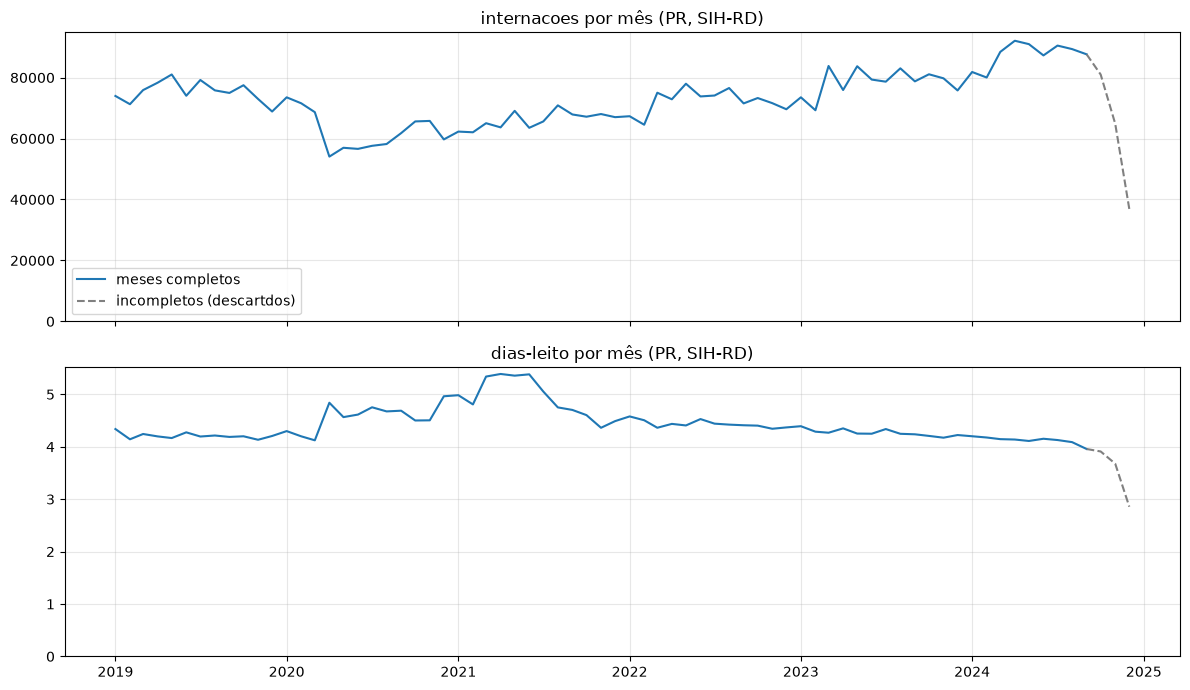

In [18]:
fig, eixos = plt.subplots(2, 1, figsize=(12,7), sharex=True)
plotar_serie(eixos[0], 'internacoes', 'internacoes por mês (PR, SIH-RD)')
plotar_serie(eixos[1], 'dias_leito', 'dias-leito por mês (PR, SIH-RD)')
eixos[0].legend()
plt.tight_layout()
plt.show()

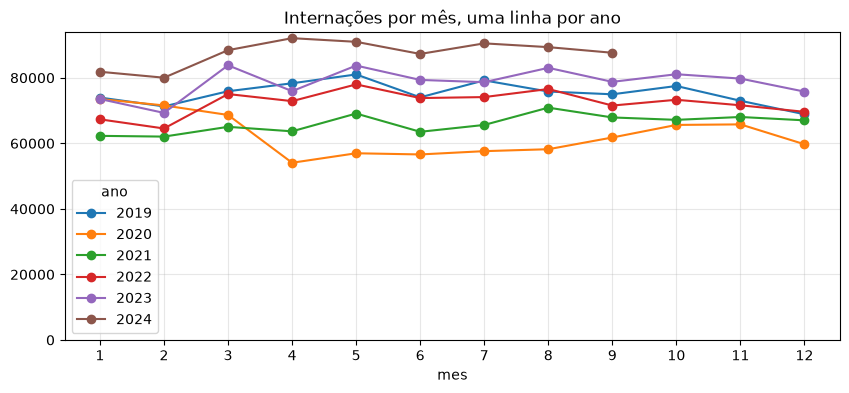

In [19]:
c = completa.copy()
c['ano'] = c['data'].dt.year
c['mes'] = c['data'].dt.month

pivo = c.pivot(index='mes', columns='ano', values='internacoes')

ax = pivo.plot(figsize=(10,4), marker='o')
ax.set_xticks(range(1,13))
ax.set_title('Internações por mês, uma linha por ano')
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
plt.show()

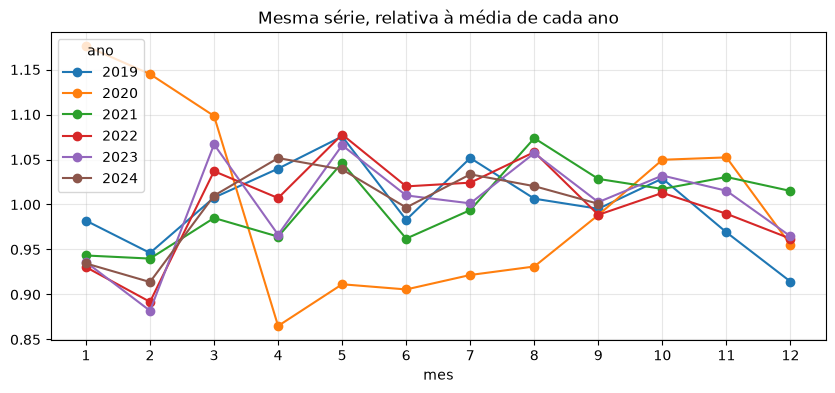

In [20]:
ax = (pivo / pivo.mean()).plot(figsize=(10, 4), marker="o")
ax.set_xticks(range(1, 13))
ax.set_title("Mesma série, relativa à média de cada ano")
ax.grid(alpha=0.3)
plt.show()

In [ ]:
pasta = Path("D:/mlops-datasus-leitos/docs/img")
pasta.mkdir(parents=True, exist_ok=True)
fig.savefig(pasta / "serie_mensal.png", dpi=150, bbox_inches="tight")

In [25]:
s = serie.copy()

s['ano'] = s['ano_mes'].str[:4]
s['mes'] = s['ano_mes'].str[4:]
s.pivot(index='mes', columns='ano', values='internacoes')

ano,2019,2020,2021,2022,2023,2024
mes,,,,,,
01,73970,73521,62280,67321,73527,81835
02,71266,71567,62053,64531,69284,80026
03,75898,68657,65032,75035,83807,88432
04,78323,54072,63664,72876,75922,92089
05,81018,56967,69090,77984,83726,90977
06,74036,56608,63519,73814,79350,87278
07,79212,57612,65611,74114,78658,90503
08,75807,58201,70887,76573,83036,89355
09,74963,61779,67898,71528,78763,87636


In [26]:
duckdb.sql(f"""
    SELECT COUNT(*) AS linhas,
           SUM(CAST(substr(DT_SAIDA, 1, 6) = ANO_CMPT || lpad(MES_CMPT, 2, '0') AS INTEGER)) AS saida_na_competencia
    FROM '{RAW}'
""").df()

,linhas,saida_na_competencia
0,5287402,2905278.0


In [27]:
duckdb.sql(f"""
    SELECT (CAST(ANO_CMPT AS INTEGER) * 12 + CAST(MES_CMPT AS INTEGER))
         - (CAST(substr(DT_SAIDA, 1, 4) AS INTEGER) * 12 + CAST(substr(DT_SAIDA, 5, 2) AS INTEGER))
           AS defasagem_meses,
           COUNT(*) AS linhas
    FROM '{RAW}'
    GROUP BY 1
    ORDER BY 1
""").df()

,defasagem_meses,linhas
0,0,2905278
1,1,1199414
2,2,608670
3,3,530787
4,4,20177
5,5,23076


In [29]:
p = s.pivot(index="mes", columns="ano", values="internacoes")
(p.loc["09"] / p.loc["08"]).round(2)

ano
2019    0.99
2020    1.06
2021    0.96
2022    0.93
2023    0.95
2024    0.98
dtype: float64

In [31]:
d = duckdb.sql(f"""SELECT (CAST(ANO_CMPT AS INTEGER) * 12 + CAST(MES_CMPT AS INTEGER))
         - (CAST(substr(DT_SAIDA, 1, 4) AS INTEGER) * 12 + CAST(substr(DT_SAIDA, 5, 2) AS INTEGER))
           AS defasagem_meses,
           COUNT(*) AS linhas
    FROM '{RAW}'
    GROUP BY 1
    ORDER BY 1
""").df()          # a mesma consulta de defasagem
d["pct"] = d["linhas"] / d["linhas"].sum() * 100
d["acumulado"] = d["pct"].cumsum()
d.head(8)

,defasagem_meses,linhas,pct,acumulado
0,0,2905278,54.947174,54.947174
1,1,1199414,22.684373,77.631548
2,2,608670,11.511703,89.143250
3,3,530787,10.038711,99.181961
4,4,20177,0.381605,99.563566
5,5,23076,0.436434,100.000000
